# طلا، دلار و نرخ بهره واقعی: رابطه واقعی یا همبستگی کاذب؟

**آموزشی است و توصیه سرمایه‌گذاری نیست.** این نوت‌بوک قیمت را پیش‌بینی نمی‌کند.

دو حرف رایج را می‌شنویم:

- وقتی نرخ بهره **واقعی** (بعد از تورم) بالا می‌رود، طلا که بهره‌ای نمی‌دهد جذابیتش کم می‌شود.
- وقتی **دلار** قوی می‌شود، طلا که با دلار قیمت می‌خورد برای بقیه دنیا گران می‌شود و قیمتش پایین می‌آید.

این‌ها را با داده می‌سنجیم و یک خطای رایج در همین سنجش را نشان می‌دهیم: **همبستگی کاذب** (spurious correlation).

**داده (از ۲۰۰۳-۰۱):**

| سری | منبع |
|---|---|
| طلا (دلار در هر اونس) | TGJU، که در نوت‌بوک‌های قبلی با آتی COMEX مقایسه شد؛ در اینجا باز هم با آتی مقایسه می‌کنیم |
| شاخص دلار (DXY) | Yahoo Finance |
| نرخ بهره واقعی ۱۰ ساله آمریکا (TIPS) | وزارت خزانه‌داری آمریکا، منبع رسمی |

فقط روزهایی را نگه می‌داریم که هر چهار سری (شامل آتی طلا) قیمت دارند. داده در repo ذخیره نیست و نوت‌بوک آن را می‌گیرد.

In [1]:
import io, json, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") if Path("../scripts/fetch_data.py").exists() else Path(".")  # repo checkout or Colab
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
(ROOT / "images").mkdir(exist_ok=True)
UA = {"User-Agent": "Mozilla/5.0"}

def get(url):
    return urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=60).read()

def yahoo(symbol):
    url = f"https://query2.finance.yahoo.com/v8/finance/chart/{symbol}?period1=967608000&period2=4102444800&interval=1d"
    res = json.loads(get(url))["chart"]["result"][0]
    s = pd.Series(res["indicators"]["quote"][0]["close"], index=pd.to_datetime(res["timestamp"], unit="s").normalize()).dropna()
    return s[~s.index.duplicated(keep="last")]

def cached(name, fetch):
    f = DATA / f"{name}.csv"
    if not f.exists():
        fetch().rename(name).to_csv(f, header=True)  # data is not stored in the repository
    return pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0]

def tgju_ons():
    url = "https://api.tgju.org/v1/market/indicator/summary-table-data/ons"
    rows = json.loads(get(url))["data"]
    return pd.Series({pd.Timestamp(r[6].replace("/", "-")): float(r[3].replace(",", "")) for r in rows}).sort_index()

def treasury_real_10y():
    parts = []
    for year in range(2003, pd.Timestamp.today().year + 1):
        url = ("https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/"
               f"{year}/all?type=daily_treasury_real_yield_curve&field_tdr_date_value={year}&page&_format=csv")
        parts.append(pd.read_csv(io.BytesIO(get(url)), parse_dates=["Date"]).set_index("Date")["10 YR"])
    return pd.concat(parts).sort_index()

gold = cached("ons_usd_close", tgju_ons)            # TGJU, USD per ounce
gold_fut = cached("gc_f", lambda: yahoo("GC=F"))    # COMEX gold futures (second source)
dxy = cached("dxy", lambda: yahoo("DX-Y.NYB"))      # ICE US Dollar Index
ry = cached("real_yield_10y", treasury_real_10y)    # US Treasury 10-year real yield (TIPS), percent

d = pd.concat({"gold": gold, "gold_fut": gold_fut, "dxy": dxy, "ry": ry}, axis=1).dropna()["2003":]
print(f"{len(d)} common days, {d.index[0].date()} to {d.index[-1].date()}")

5928 common days, 2003-01-02 to 2026-10-16


## ۱. اول سطح قیمت‌ها (و دام آن)

ساده‌ترین کار: لگاریتم قیمت طلا را روی نرخ بهره واقعی و روی لگاریتم DXY رگرسیون کنیم.

In [2]:
lg = np.log(d["gold"])
for name, x in [("10y real yield (%)", d["ry"]), ("log DXY", np.log(d["dxy"]))]:
    X = np.column_stack([np.ones(len(d)), x])
    beta = np.linalg.lstsq(X, lg, rcond=None)[0]
    res = lg - X @ beta
    r2 = 1 - res.var() / lg.var()
    dw = (np.diff(res) ** 2).sum() / (res ** 2).sum()
    print(f"log gold ~ {name:18s}: corr {np.corrcoef(x, lg)[0, 1]:+.2f}, R2 {r2:.2f}, Durbin-Watson {dw:.4f}")

log gold ~ 10y real yield (%): corr -0.32, R2 0.10, Durbin-Watson 0.0005
log gold ~ log DXY           : corr +0.35, R2 0.12, Durbin-Watson 0.0010


همبستگی سطح طلا با نرخ بهره واقعی ۰٫۳۲- و با دلار ۰٫۳۵+ است. R² حدود ۰٫۱۰ و ۰٫۱۲.

دو نشانه می‌گویند این عددها را نباید جدی گرفت:

- **دوربین-واتسون** (Durbin-Watson) تقریباً صفر است، یعنی باقی‌مانده‌های رگرسیون خودشان مثل یک قدم‌زدن تصادفی رفتار می‌کنند.
- قیمت‌ها **ایستا نیستند**: هر دو سری سال‌ها در یک جهت رفته‌اند. دو سری بی‌ربط که هر دو بالا و پایین می‌روند هم همبستگی بالا می‌دهند.

برای دیدن این، دو قدم‌زدن تصادفی **کاملاً مستقل** (بدون هیچ رابطه‌ای) به همان طول می‌سازیم و R² را حساب می‌کنیم:

In [3]:
rng = np.random.default_rng(0)
n = len(d)
r2 = np.array([np.corrcoef(np.cumsum(rng.normal(size=n)), np.cumsum(rng.normal(size=n)))[0, 1] ** 2 for _ in range(2000)])
obs = {"real yield": np.corrcoef(d["ry"], lg)[0, 1] ** 2, "DXY": np.corrcoef(np.log(d["dxy"]), lg)[0, 1] ** 2}
print(f"two UNRELATED random walks of the same length: median R2 {np.median(r2):.2f}, "
      f"P(R2 > 0.3) = {(r2 > .3).mean():.0%}, P(R2 > 0.5) = {(r2 > .5).mean():.0%}")
for k, v in obs.items():
    print(f"observed levels R2 with {k:10s}: {v:.2f}  -> share of unrelated pairs that look at least this related: {(r2 >= v).mean():.0%}")

two UNRELATED random walks of the same length: median R2 0.19, P(R2 > 0.3) = 35%, P(R2 > 0.5) = 17%
observed levels R2 with real yield: 0.10  -> share of unrelated pairs that look at least this related: 63%
observed levels R2 with DXY       : 0.12  -> share of unrelated pairs that look at least this related: 60%


حدود **۶۰ تا ۶۳٪** از جفت‌های کاملاً بی‌ربط، R² برابر یا بیشتر از مقدار مشاهده‌شده ما دارند. یعنی رابطه سطحی طلا با این دو سری را نمی‌شود از «هیچ رابطه‌ای» تشخیص داد.

> قاعده: قیمت‌ها را روی قیمت‌ها رگرسیون نکن. تغییرها (بازده) را بسنج.

## ۲. حالا بازده‌ها

بازده لگاریتمی طلا و DXY، و **تغییر** نرخ بهره واقعی (به واحد درصد، چون نرخ از اول بازده است). همبستگی را در سه افق می‌سنجیم:

In [4]:
r = pd.DataFrame({
    "gold": np.log(d["gold"]).diff(),
    "dxy": np.log(d["dxy"]).diff(),
    "d_real_yield": d["ry"].diff(),          # change in percentage points
}).dropna()

def horizon(rule):
    x = pd.DataFrame({
        "gold": np.log(d["gold"]).resample(rule).last().diff(),
        "dxy": np.log(d["dxy"]).resample(rule).last().diff(),
        "d_real_yield": d["ry"].resample(rule).last().diff(),
    }).dropna()
    return len(x), x["gold"].corr(x["dxy"]), x["gold"].corr(x["d_real_yield"])

rows = {"daily": (len(r), r["gold"].corr(r["dxy"]), r["gold"].corr(r["d_real_yield"])),
        "weekly": horizon("W-FRI"), "monthly": horizon("ME")}
pd.DataFrame(rows, index=["n", "corr with DXY", "corr with change in real yield"]).T.round(3)

,n,corr with DXY,corr with change in real yield
daily,5927.0,-0.438,-0.247
weekly,1241.0,-0.473,-0.283
monthly,285.0,-0.461,-0.453


In [5]:
# robustness: the same daily correlations with COMEX futures instead of TGJU for gold
rf = pd.DataFrame({"gold": np.log(d["gold_fut"]).diff(), "dxy": r["dxy"], "d_real_yield": r["d_real_yield"]}).dropna()
print("with futures: corr DXY", round(rf["gold"].corr(rf["dxy"]), 3), "| corr d_real_yield", round(rf["gold"].corr(rf["d_real_yield"]), 3))

with futures: corr DXY -0.405 | corr d_real_yield -0.205


- با DXY همبستگی **منفی و قوی‌تر** است (حدود ۰٫۴۴- روزانه).
- با تغییر نرخ بهره واقعی ضعیف‌تر است (حدود ۰٫۲۵- روزانه)، ولی در افق ماهانه تا ۰٫۴۵- بالا می‌رود.

دلیل احتمالی این پله‌پله شدن: قیمت طلا، DXY و نرخ خزانه‌داری دقیقاً هم‌زمان ثبت نمی‌شوند و این **نویز اندازه‌گیری** همبستگی روزانه را کم می‌کند؛ هرچه افق بلندتر، اثرش کمتر. با آتی طلا به‌جای TGJU همبستگی روزانه حتی کمی پایین‌تر است (۰٫۴۱- و ۰٫۲۱-)، که با همین توضیح می‌خواند، ولی این را اثبات نکرده‌ایم.

### رگرسیون روزانه
بازده طلا را روی بازده DXY و تغییر نرخ بهره واقعی رگرسیون می‌کنیم. خطای استاندارد نیوی-وست (HAC) برای خودهمبستگی و ناهم‌واریانسی:

In [6]:
def ols_hac(y, X, lags=5):
    """OLS with Newey-West (HAC) standard errors."""
    X = np.column_stack([np.ones(len(y)), X])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    xe = X * e[:, None]
    S = xe.T @ xe
    for l in range(1, lags + 1):
        G = xe[l:].T @ xe[:-l]
        S += (1 - l / (lags + 1)) * (G + G.T)
    XtXi = np.linalg.inv(X.T @ X)
    se = np.sqrt(np.diag(XtXi @ S @ XtXi))
    return beta, se, 1 - e.var() / y.var()

beta, se, r2 = ols_hac(r["gold"].values, r[["dxy", "d_real_yield"]].values)
out = pd.DataFrame({"coef": beta, "HAC t-stat": beta / se}, index=["const", "DXY return", "change in real yield (pp)"]).round(4)
print(f"R2 = {r2:.3f}")
out

R2 = 0.213


,coef,HAC t-stat
const,0.0004,3.3631
DXY return,-0.9451,-22.4920
change in real yield (pp),-0.0329,-8.0549


- R² حدود **۰٫۲۱** است: بازده‌های DXY و نرخ واقعی فقط حدود یک‌پنجم تغییرات روزانه طلا را توضیح می‌دهند؛ **حدود ۷۹٪ را توضیح نمی‌دهند**.
- ضریب DXY حدود ۰٫۹۵- است: روزی که شاخص دلار ۱٪ بالا رفته، طلا به‌طور میانگین حدود ۰٫۹۵٪ پایین آمده. ضریب نرخ واقعی ۰٫۰۳۳- است: ۱۰ نقطه پایه (۰٫۱ واحد درصد) افزایش نرخ واقعی، به‌طور میانگین حدود ۰٫۳۳٪ افت طلا.
- هر دو ضریب از نظر آماری معنادارند (t حدود ۲۲- و ۸-)، ولی «معنادار» یعنی صفر نیست، نه اینکه پیش‌بینی‌کننده خوبی باشند.

> این **هم‌زمان** است: ببینیم وقتی دلار تکان می‌خورد طلا چه می‌کند. پیش‌بینی نیست. دلار فردا را نمی‌دانیم.

## ۳. ثبات رابطه

همبستگی را برای هر سال جدا حساب می‌کنیم:

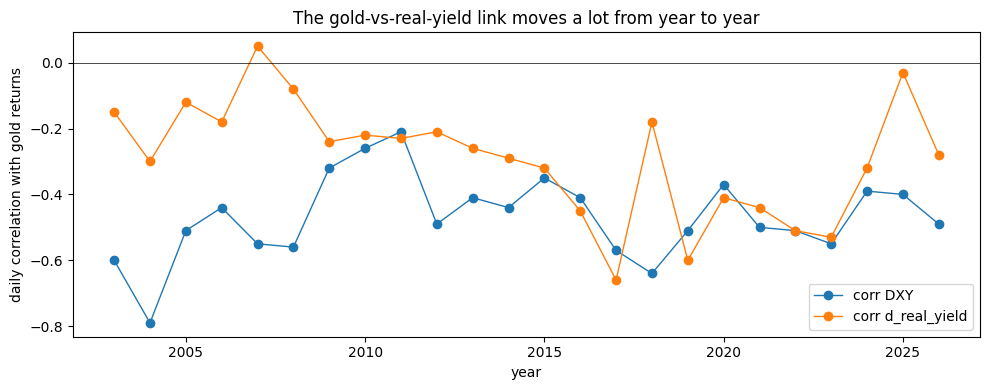

,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
corr DXY,-0.60,-0.79,-0.51,-0.44,-0.55,-0.56,-0.32,-0.26,-0.21,-0.49,...,-0.57,-0.64,-0.51,-0.37,-0.50,-0.51,-0.55,-0.39,-0.40,-0.49
corr d_real_yield,-0.15,-0.30,-0.12,-0.18,0.05,-0.08,-0.24,-0.22,-0.23,-0.21,...,-0.66,-0.18,-0.60,-0.41,-0.44,-0.51,-0.53,-0.32,-0.03,-0.28


In [7]:
by_year = r.groupby(r.index.year).apply(lambda x: pd.Series({
    "corr DXY": x["gold"].corr(x["dxy"]), "corr d_real_yield": x["gold"].corr(x["d_real_yield"])})).round(2)
fig, ax = plt.subplots(figsize=(10, 4))
by_year.plot(ax=ax, marker="o", lw=1)
ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("daily correlation with gold returns"); ax.set_xlabel("year")
ax.set_title("The gold-vs-real-yield link moves a lot from year to year")
plt.tight_layout(); plt.savefig(ROOT / "images" / "gold-dollar-rates-by-year.png", dpi=130); plt.show()
by_year.T

In [8]:
# out of sample: fit on 2003-2012, evaluate on 2013-2026
train, test = r[:"2012"], r["2013":]
b, _, r2_in = ols_hac(train["gold"].values, train[["dxy", "d_real_yield"]].values)
Xt = np.column_stack([np.ones(len(test)), test[["dxy", "d_real_yield"]].values])
e = test["gold"].values - Xt @ b
print(f"R2 in sample (2003-2012): {r2_in:.3f}")
print(f"R2 out of sample (2013-2026), using the 2003-2012 coefficients: {1 - (e ** 2).sum() / ((test['gold'] - test['gold'].mean()) ** 2).sum():.3f}")
print("coefficients 2003-2012:", dict(zip(['const', 'dxy', 'd_real_yield'], b.round(3))))
b2, _, r2_late = ols_hac(test["gold"].values, test[["dxy", "d_real_yield"]].values)
print("coefficients 2013-2026:", dict(zip(['const', 'dxy', 'd_real_yield'], b2.round(3))), "R2", round(r2_late, 3))

R2 in sample (2003-2012): 0.210
R2 out of sample (2013-2026), using the 2003-2012 coefficients: 0.203
coefficients 2003-2012: {'const': np.float64(0.001), 'dxy': np.float64(-0.996), 'd_real_yield': np.float64(-0.015)}
coefficients 2013-2026: {'const': np.float64(0.0), 'dxy': np.float64(-0.861), 'd_real_yield': np.float64(-0.052)} R2 0.23


- **دلار:** همبستگی با طلا در هر ۲۴ سال منفی است (از حدود ۰٫۲۱- تا ۰٫۷۹-). رابطه ثابت‌تر است.
- **نرخ بهره واقعی:** از ۰٫۰۵+ در ۲۰۰۷ تا ۰٫۶۶- در ۲۰۱۷. در ۲۰۲۵ تقریباً صفر شد (۰٫۰۳-). چرا؟ نمی‌دانیم؛ این‌جا بررسی‌اش نکرده‌ایم.
- **ضریب نرخ واقعی** در دو نیمه تقریباً سه برابر شد (۰٫۰۱۵- در ۲۰۰۳ تا ۲۰۱۲، ۰٫۰۵۲- در ۲۰۱۳ تا ۲۰۲۶). پس «هر ۱۰ نقطه پایه چند درصد» عدد ثابتی نیست.
- با ضرایب ۲۰۰۳ تا ۲۰۱۲ هم‌زمان R² در ۲۰۱۳ تا ۲۰۲۶ حدود ۰٫۲۰ می‌شود، نزدیک به درون‌نمونه (۰٫۲۱). یعنی **بیشترِ رابطه از DXY می‌آید**، که پایدار است.

## ۴. محدودیت‌ها

۱. **هم‌زمان‌اند، نه علّی:** نمی‌دانیم دلار طلا را می‌برد، طلا دلار را، یا چیز سومی هر دو را.
۲. **قیمت طلا با دلار ثبت می‌شود:** رابطه با DXY تا حدی مکانیکی است، نه فقط «اقتصادی».
۳. **زمان‌بندی:** سه سری ساعت بسته‌شدن یکسان ندارند؛ همبستگی روزانه کمتر از واقع است.
۴. **R² حدود ۰٫۲** یعنی بیشترِ حرکت طلا را این دو توضیح نمی‌دهند (تقاضای بانک‌های مرکزی، ژئوپلیتیک، ... را بررسی نکرده‌ایم).
۵. **نرخ بهره واقعی ۱۰ ساله آمریکا:** فقط یکی از چند تعریف ممکن است.

## جمع‌بندی

- رگرسیون **سطح** قیمت طلا روی دلار یا نرخ بهره بی‌معناست: ۶۰٪ جفت‌های بی‌ربط هم همین‌قدر «مرتبط» به نظر می‌رسند.
- روی **بازده‌ها** رابطه واقعی است: با دلار منفی و پایدار (حدود ۰٫۴۴-)، با نرخ واقعی منفی ولی ضعیف‌تر و ناپایدار.
- دو متغیر با هم حدود ۲۱٪ تغییرات روزانه طلا را توضیح می‌دهند.
- این توصیف هم‌زمان است و پیش‌بینی نیست.

**گام بعدی:** آیا این رابطه در ایران هم هست؟ طلا به ریال، و سهم دلار و اونس در آن.